In [14]:
import numpy as np
import matplotlib.pyplot as plt
from kamo.atom_properties.k39 import Potassium39
%matplotlib inline

atom = Potassium39()

# one entry per measurement: transducer current (A) and measured Raman transition frequency (Hz)
i_transducer = np.array([176.5, 182.0,182.5])
frequency_raman = np.array([119.3978e6, 119.4635753e6, 119.468811e6])

In [15]:
F_i = 1
mf_i = -1

F_f = 1
mf_f = 0

# Field range searched (G). The splitting rises steadily over it, so each frequency
# gives one field; a frequency above f(B_max) raises an error.
B_range = (1., 550.)

def splitting_mhz(b):
    return abs(atom.get_microwave_transition_frequency(4,0,.5,F_i,mf_i,F_f,mf_f,B=b))

# one field sweep over B_range, inverted by interpolation
B = np.atleast_1d(atom.get_magnetic_field_from_splitting(
    (4,0,.5,F_i,mf_i), (4,0,.5,F_f,mf_f), frequency_raman, B_bounds_G=B_range))

for i, f, b in zip(i_transducer, frequency_raman, B):
    print(f'{i:.3f} A, {f/1e6:.6f} MHz -> B = {b:.3f} G (check: {splitting_mhz(b):.6f} MHz)')

176.500 A, 119.397800 MHz -> B = 504.909 G (check: 119.397756 MHz)
182.000 A, 119.463575 MHz -> B = 520.496 G (check: 119.463552 MHz)
182.500 A, 119.468811 MHz -> B = 521.910 G (check: 119.468775 MHz)


B = 2.8337 G/A * I + 4.766 G


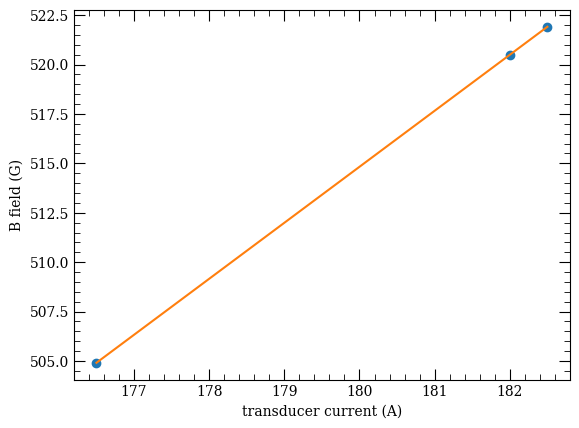

In [16]:
slope, intercept = np.polyfit(i_transducer, B, 1)
print(f'B = {slope:.4f} G/A * I + {intercept:.3f} G')

ii = np.linspace(i_transducer.min(), i_transducer.max(), 100)
fig, ax = plt.subplots()
ax.plot(i_transducer, B, 'o')
ax.plot(ii, slope*ii + intercept, '-')
ax.set_xlabel('transducer current (A)')
ax.set_ylabel('B field (G)')
plt.show()

Current -> transition frequency (uses the fit line above)

In [20]:
i_query = 183.5  # transducer current (A)

b_query = slope*i_query + intercept
print(f'{i_query:.3f} A -> B = {b_query:.3f} G -> {splitting_mhz(b_query):.6f} MHz')

183.500 A -> B = 524.745 G -> 119.478952 MHz


Outer coil: transducer current <-> supply set-point voltage <-> supply current

In [18]:
from kexp.control.big_coil import igbt_magnet, V_FULLSCALE_DAC
from kexp.calibrations import magnets as cal

# same calibration as the outer coil in kexp.base.devices
outer_coil = igbt_magnet(max_current=500., max_voltage=80.,
    slope_current_per_vdac_supply=cal.slope_i_transducer_per_v_setpoint_supply_outer,
    offset_current_per_vdac_supply=cal.offset_i_transducer_per_v_setpoint_supply_outer,
    slope_current_per_vdac_pid=cal.slope_i_transducer_per_v_setpoint_pid_outer,
    offset_current_per_vdac_pid=cal.offset_i_transducer_per_v_setpoint_pid_outer)

i_transducer_query = 197.5  # A
v_setpoint_supply = outer_coil.current_to_supply_vdac(i_transducer_query)    # V; back: outer_coil.supply_vdac_to_current(v)
i_supply = v_setpoint_supply * outer_coil.max_current / V_FULLSCALE_DAC      # A, nominal (500 A per 10 V)
v_setpoint_pid = outer_coil.current_to_pid_vdac(i_transducer_query)          # V; back: outer_coil.pid_vdac_to_current(v)
print(f'{i_transducer_query:.3f} A transducer -> supply set point {v_setpoint_supply:.4f} V '
      f'(supply current {i_supply:.3f} A), PID set point {v_setpoint_pid:.4f} V')

197.500 A transducer -> supply set point 3.8713 V (supply current 193.565 A), PID set point 4.9443 V


## Scattering length, |1,-1> + |1,-1>

Kokkelmans coupled-channels data in k-jam/je (`cc_1G_1000G`, column 0 = Re(a) in a0, 0.5 G grid, 1-1000 G).
Linear interpolation; near a resonance the 0.5 G grid is too coarse to trust the value.

In [19]:
import os
from pathlib import Path

scat_dir = Path(os.environ.get('code', '../../../..')) / 'k-jam/je/k in b field calcs/Scattering length data/Kokkelmans_data_2/cc_1G_1000G'
B_scat = np.loadtxt(scat_dir / 'Bval.txt')
a_scat = np.loadtxt(scat_dir / 'data.txt')[:, 0]

i_query_a = 193.615  # transducer current (A)

b_query_a = slope*i_query_a + intercept
print(f'{i_query_a:.3f} A -> B = {b_query_a:.3f} G -> a(|1,-1>) = {np.interp(b_query_a, B_scat, a_scat):.1f} a0')

193.615 A -> B = 553.408 G -> a(|1,-1>) = 185.7 a0
